# Demo 1. 회피 공격과 적대적 예제 (FGSM)
**아주대학교 인공지능 보안 1회차 · 18:00~18:50 세션 데모**

| 단계 | 내용 | 소요 |
|---|---|---|
| 1 | 손글씨 숫자 분류 모델 학습 (정확도 ~95%) | 2분 |
| 2 | FGSM으로 적대적 예제 생성 → 사람 눈엔 같은데 모델은 오답 | 4분 |
| 3 | ε(섭동 크기)에 따른 정확도 붕괴 곡선 | 2분 |
| 4 | 전이 공격 (블랙박스 모델도 속는다) | 2분 |
| 5 | 방어: 적대적 학습 · 입력 변환(Feature Squeezing) | 4분 |

> 외부 다운로드 없이 scikit-learn 내장 `digits`(8×8 이미지, 1,797장)만 사용합니다. 강의실 네트워크가 불안정해도 동작합니다.

train: (1257, 64)  test: (540, 64)


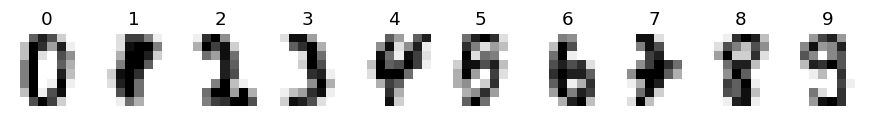

In [1]:
# 필요 패키지: numpy, scikit-learn, matplotlib (Colab/Anaconda 기본 포함)
# 로컬 환경에서 없으면: !pip install -q numpy scikit-learn matplotlib
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 110
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

X, y = load_digits(return_X_y=True)
X = X / 16.0                                   # 픽셀값 0~1 정규화
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("train:", Xtr.shape, " test:", Xte.shape)

fig, ax = plt.subplots(1, 10, figsize=(10, 1.3))
for i in range(10):
    ax[i].imshow(Xtr[ytr == i][0].reshape(8, 8), cmap="gray_r"); ax[i].set_title(i); ax[i].axis("off")
plt.show()

## 1. 피해 모델(Victim) 학습
FGSM 수식을 눈으로 따라갈 수 있도록 **Softmax 회귀를 NumPy로 직접 구현**합니다.
입력에 대한 손실의 기울기는 해석적으로 구할 수 있습니다:  $\nabla_x L = W\,(p - y_{onehot})$

In [2]:
def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

class SoftmaxModel:
    def __init__(self, W, b): self.W, self.b = W, b
    def proba(self, X):   return softmax(X @ self.W + self.b)
    def predict(self, X): return self.proba(X).argmax(1)
    def acc(self, X, y):  return (self.predict(X) == y).mean()
    def input_grad(self, X, y):          # dLoss/dX  ← 공격자가 쓰는 정보
        return (self.proba(X) - np.eye(10)[y]) @ self.W.T

def fgsm(model, X, y, eps):
    """Fast Gradient Sign Method (Goodfellow et al., 2015)"""
    return np.clip(X + eps * np.sign(model.input_grad(X, y)), 0, 1)

def train_softmax(X, y, adv_eps=0.0, epochs=300, lr=0.5, l2=1e-3):
    W, b, Y = np.zeros((X.shape[1], 10)), np.zeros(10), np.eye(10)[y]
    for _ in range(epochs):
        Xb, Yb = X, Y
        if adv_eps > 0:                    # 적대적 학습: 매 epoch 현재 모델 기준 FGSM 예제를 섞음
            m = SoftmaxModel(W, b)
            Xb = np.vstack([X, fgsm(m, X, y, adv_eps)]); Yb = np.vstack([Y, Y])
        P = softmax(Xb @ W + b)
        W -= lr * (Xb.T @ (P - Yb) / len(Xb) + l2 * W); b -= lr * (P - Yb).mean(0)
    return SoftmaxModel(W, b)

victim = train_softmax(Xtr, ytr)
print(f"Clean test accuracy: {victim.acc(Xte, yte):.1%}")

Clean test accuracy: 95.4%


## 2. 적대적 예제 만들기
$x_{adv} = \mathrm{clip}(x + \epsilon \cdot \mathrm{sign}(\nabla_x L(\theta, x, y)))$
- 손실을 **가장 빠르게 키우는 방향**으로 모든 픽셀을 ε만큼 동시에 이동
- **강사 포인트**: “모델 파라미터는 그대로. 바뀐 건 입력뿐이다 → 추론 단계(Inference-time) 공격”

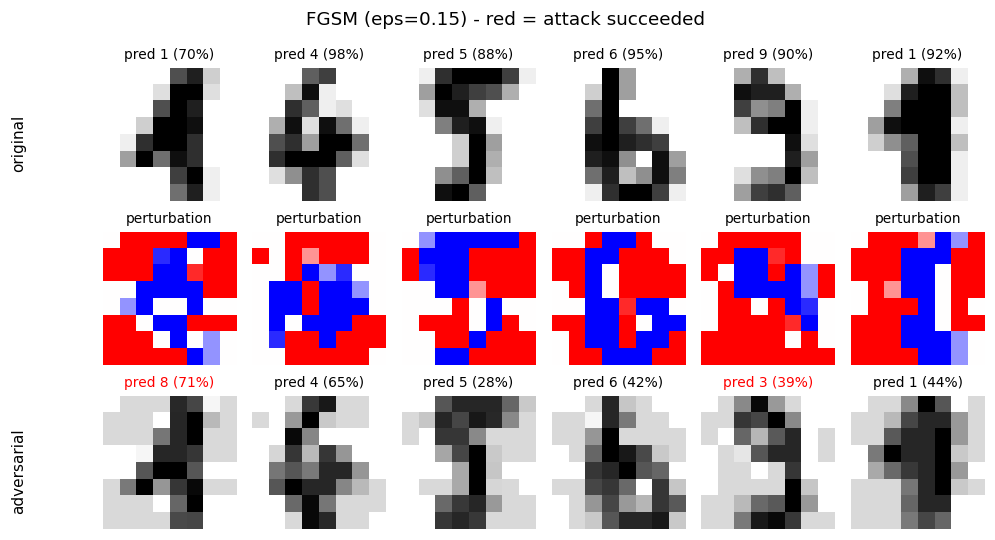

In [3]:
EPS = 0.15
idx = np.where(victim.predict(Xte) == yte)[0][:6]          # 원래 맞히던 샘플 6개
Xa = fgsm(victim, Xte[idx], yte[idx], EPS)

fig, ax = plt.subplots(3, 6, figsize=(9, 5))
for j, i in enumerate(idx):
    p0, pa = victim.proba(Xte[i:i+1])[0], victim.proba(Xa[j:j+1])[0]
    ax[0, j].imshow(Xte[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    ax[0, j].set_title(f"pred {p0.argmax()} ({p0.max():.0%})", fontsize=9)
    ax[1, j].imshow((Xa[j] - Xte[i]).reshape(8, 8), cmap="bwr", vmin=-EPS, vmax=EPS)
    ax[1, j].set_title("perturbation", fontsize=9)
    ax[2, j].imshow(Xa[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    ax[2, j].set_title(f"pred {pa.argmax()} ({pa.max():.0%})", fontsize=9,
                       color="red" if pa.argmax() != yte[i] else "black")
for a in ax.ravel(): a.axis("off")
ax[0, 0].text(-6, 4, "original", rotation=90, va="center"); ax[2, 0].text(-6, 4, "adversarial", rotation=90, va="center")
plt.suptitle(f"FGSM (eps={EPS}) - red = attack succeeded"); plt.tight_layout(); plt.show()

## 3. ε 에 따른 정확도 붕괴
**질문 던지기**: “ε=0.1이면 픽셀 밝기를 10%만 바꾼 것입니다. 정확도는 얼마나 떨어질까요?” → 예측을 받은 뒤 실행

eps=0     accuracy=95.4%
eps=0.02  accuracy=93.5%
eps=0.05  accuracy=87.2%
eps=0.08  accuracy=77.8%
eps=0.1   accuracy=68.5%
eps=0.15  accuracy=45.2%
eps=0.2   accuracy=18.9%
eps=0.25  accuracy=4.4%


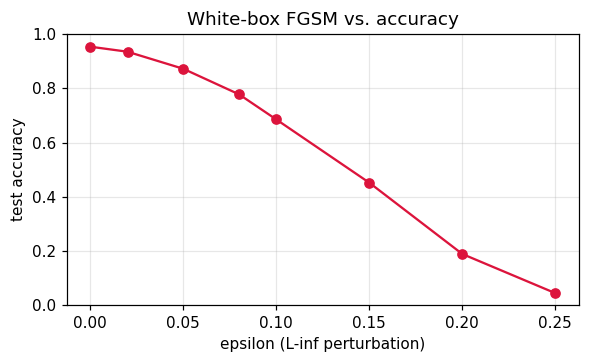

In [4]:
eps_list = [0, 0.02, 0.05, 0.08, 0.1, 0.15, 0.2, 0.25]
acc_std = [victim.acc(fgsm(victim, Xte, yte, e), yte) for e in eps_list]
for e, a in zip(eps_list, acc_std): print(f"eps={e:<5} accuracy={a:.1%}")
plt.figure(figsize=(6, 3.2)); plt.plot(eps_list, acc_std, "o-", c="crimson")
plt.xlabel("epsilon (L-inf perturbation)"); plt.ylabel("test accuracy"); plt.ylim(0, 1); plt.grid(alpha=.3)
plt.title("White-box FGSM vs. accuracy"); plt.show()

## 4. 전이 공격 (Transferability) — 블랙박스도 안전하지 않다
공격자가 **내부를 모르는 다른 구조의 모델(MLP 신경망)**에, 위에서 만든 적대적 예제를 그대로 넣어봅니다.
→ 대리 모델(surrogate)로 만든 공격이 실제 서비스 모델에도 통하는 현상

In [5]:
blackbox = MLPClassifier(hidden_layer_sizes=(64,), max_iter=800, random_state=0).fit(Xtr, ytr)
print(f"Black-box MLP clean accuracy: {blackbox.score(Xte, yte):.1%}")
for e in [0.05, 0.1, 0.15, 0.2]:
    Xa_all = fgsm(victim, Xte, yte, e)            # victim(대리 모델) 기울기로만 생성
    print(f"eps={e:<4}  surrogate acc={victim.acc(Xa_all, yte):.1%}   ->  black-box MLP acc={blackbox.score(Xa_all, yte):.1%}")

Black-box MLP clean accuracy: 97.8%
eps=0.05  surrogate acc=87.2%   ->  black-box MLP acc=87.4%
eps=0.1   surrogate acc=68.5%   ->  black-box MLP acc=65.2%
eps=0.15  surrogate acc=45.2%   ->  black-box MLP acc=31.1%
eps=0.2   surrogate acc=18.9%   ->  black-box MLP acc=10.2%


## 5. 방어 ① 적대적 학습 (Adversarial Training)
학습 중 FGSM 예제를 함께 학습 → 결정 경계에 여유(margin)를 확보
- **트레이드오프**: 깨끗한 데이터 정확도 소폭 하락, 학습 비용 증가, 학습에 쓰지 않은 강한 공격엔 여전히 취약

eps     standard  adv-trained
0          95.4%        94.4%
0.02       93.5%        93.9%
0.05       87.2%        89.1%
0.08       77.8%        79.4%
0.1        68.5%        73.9%
0.15       45.2%        55.4%
0.2        18.9%        33.9%
0.25        4.4%        12.6%


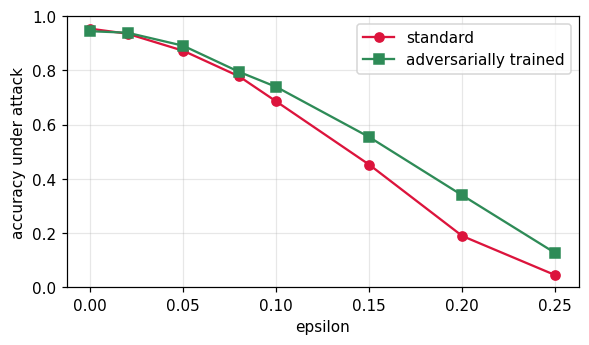

In [6]:
robust = train_softmax(Xtr, ytr, adv_eps=0.15)
acc_rob = [robust.acc(fgsm(robust, Xte, yte, e), yte) for e in eps_list]   # 방어 모델 자신을 화이트박스 공격
print(f"{'eps':<6}{'standard':>10}{'adv-trained':>13}")
for e, a, r in zip(eps_list, acc_std, acc_rob): print(f"{e:<6}{a:>10.1%}{r:>13.1%}")
plt.figure(figsize=(6, 3.2))
plt.plot(eps_list, acc_std, "o-", c="crimson", label="standard")
plt.plot(eps_list, acc_rob, "s-", c="seagreen", label="adversarially trained")
plt.xlabel("epsilon"); plt.ylabel("accuracy under attack"); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend(); plt.show()

## 6. 방어 ② 입력 변환 — Feature Squeezing
입력의 비트 깊이를 줄여(양자화) 미세한 섭동을 제거하고, **원본 예측과 압축 후 예측이 다르면 공격으로 탐지**합니다.
(Xu et al., 2018) — 단, 방어 방식을 아는 **적응형 공격(adaptive attack)** 에는 우회될 수 있다는 점을 꼭 언급.

In [7]:
def squeeze(X, levels=3):      # 각 픽셀을 3단계(0, .5, 1)로 양자화
    return np.round(X * (levels - 1)) / (levels - 1)

for e in [0.05, 0.1, 0.15]:
    Xa_all = fgsm(victim, Xte, yte, e)
    acc_sq = victim.acc(squeeze(Xa_all), yte)
    flagged_adv = (victim.predict(Xa_all) != victim.predict(squeeze(Xa_all))).mean()
    flagged_clean = (victim.predict(Xte) != victim.predict(squeeze(Xte))).mean()
    print(f"eps={e:<4} acc no-defense={victim.acc(Xa_all, yte):.1%}  with squeeze={acc_sq:.1%}  "
          f"| detect rate adv={flagged_adv:.1%}  false-alarm clean={flagged_clean:.1%}")

eps=0.05 acc no-defense=87.2%  with squeeze=90.6%  | detect rate adv=6.9%  false-alarm clean=3.1%
eps=0.1  acc no-defense=68.5%  with squeeze=78.1%  | detect rate adv=13.7%  false-alarm clean=3.1%
eps=0.15 acc no-defense=45.2%  with squeeze=58.0%  | detect rate adv=21.3%  false-alarm clean=3.1%


## 정리 (슬라이드로 복귀)
| 구분 | 관찰 결과 |
|---|---|
| 공격 | 사람이 구분 못 할 수준의 섭동만으로 정확도 급락 |
| 전이성 | 다른 구조의 블랙박스 모델에도 공격이 전이 → “모델 비공개 ≠ 안전” |
| 방어 | 적대적 학습·입력 변환은 **완화**이지 **해결**이 아님 → 다층 방어 + 모니터링 |

**실습 과제(선택)**: `EPS`를 바꾸거나, `squeeze(levels=2)`로 바꿔 탐지율·오탐율의 트레이드오프를 확인해 보세요.